# 01 · Análisis exploratorio del dataset ampliado

EP2 · Machine Learning · Waymo Open Dataset v2.0.1 (`lidar_box`)

**Objetivo de este notebook:** entender los datos con los que vamos a comparar modelos: tamaño, calidad, balance de clases y relaciones entre variables. Lo que encontremos aquí justifica las decisiones de preparación y de validación de los notebooks siguientes.

In [1]:
import sys
sys.path.append("..")  # permite importar el paquete src/ desde notebooks/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.data_preprocessing import (
    RANDOM_STATE,
    agregar_distancia_vehiculo,
    agregar_nombre_tipo,
    cargar_segmentos,
)

sns.set_theme(style="whitegrid")
PLOTS = Path("../results/plots")
PLOTS.mkdir(parents=True, exist_ok=True)
ORDEN_CLASES = ["Vehículo", "Señal", "Peatón", "Ciclista"]

## 1. Carga del dataset

En la EP1 trabajamos con un solo segmento. Ahora usamos **30 segmentos del split `training`**, elegidos al azar con semilla 42, para tener todas las clases y suficientes datos para comparar modelos.

In [2]:
df = cargar_segmentos("../data/raw/lidar_box")
df = agregar_nombre_tipo(df)
df = agregar_distancia_vehiculo(df)

print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Segmentos: {df['key_segment_context_name'].nunique()}")
print(f"Objetos únicos (laser_object_id): {df['key_laser_object_id'].nunique():,}")
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
df.head()

Filas: 332,741 | Columnas: 23 | Segmentos: 30
Objetos únicos (laser_object_id): 3,218
Memoria: 77.4 MB


,key_segment_context_name,key_frame_timestamp_micros,key_laser_object_id,box_center_x,box_center_y,box_center_z,box_size_x,box_size_y,box_size_z,box_heading,...,speed_x,speed_y,speed_z,acceleration_x,acceleration_y,acceleration_z,difficulty_level_detection,difficulty_level_tracking,type_nombre,distancia_vehiculo
0,11388947676680954806_5427_320_5447_320,1507250061983417,-xXZ_7mS1RHPEeVZdKgYrg,42.642800,-10.019463,1.234657,0.084193,0.381692,0.42,3.112560,...,-0.012240,-8.525624e-03,1.088642e-29,-7.866290e-15,1.574379e-14,-1.209603e-29,NaN,NaN,Señal,43.821483
1,11388947676680954806_5427_320_5447_320,1507250061983417,0UDS8SPu8754kysBpccXdw,9.600673,3.658436,0.984719,5.161417,2.293861,2.00,0.004709,...,7.890882,-4.755430e+00,1.334727e-02,3.017314e-01,-2.447228e-01,1.735830e-02,NaN,NaN,Vehículo,10.321180
2,11388947676680954806_5427_320_5447_320,1507250061983417,1fTcRPS-nwlv3dWhNc-YUg,-40.674086,-10.883407,0.687665,1.029718,0.846732,1.12,1.675039,...,0.000000,9.500879e-29,2.969025e-30,0.000000e+00,-1.055653e-28,-3.298917e-30,NaN,NaN,Señal,42.110601
3,11388947676680954806_5427_320_5447_320,1507250061983417,21Ec8erJVKlPJXiPRFLLgQ,2.663006,19.620184,0.400540,5.109753,2.103190,1.85,-3.127563,...,0.000000,9.500879e-29,-1.278951e-02,0.000000e+00,-1.055653e-28,-1.012400e-14,NaN,NaN,Vehículo,19.804132
4,11388947676680954806_5427_320_5447_320,1507250061983417,2qp14n7hv00HnDOH8vVkiw,-56.608132,29.040270,0.094247,0.130571,0.259285,0.39,0.001573,...,-0.017552,-9.766365e-03,1.666623e-02,3.978493e-13,2.461051e-13,-1.045462e-15,NaN,NaN,Señal,63.622533


## 2. Distribución de clases (variable objetivo de la clasificación)

             detecciones  porcentaje
type_nombre                         
Vehículo          162697       48.90
Señal              96564       29.02
Peatón             71714       21.55
Ciclista            1766        0.53


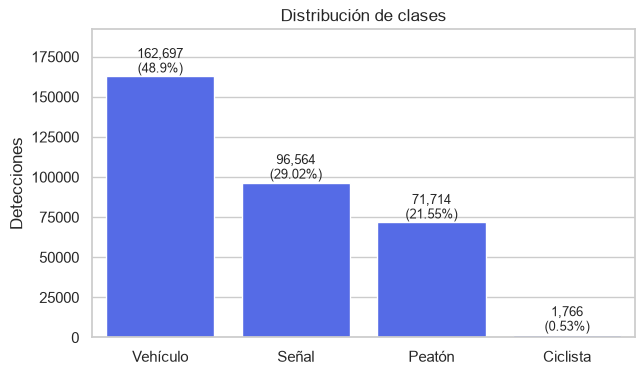

In [3]:
conteo = df["type_nombre"].value_counts().reindex(ORDEN_CLASES).fillna(0).astype(int)
porcentaje = (conteo / len(df) * 100).round(2)
print(pd.DataFrame({"detecciones": conteo, "porcentaje": porcentaje}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=conteo.index, y=conteo.values, ax=ax, color="#3D5AFE")
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({porcentaje.iloc[i]}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Detecciones")
ax.set_xlabel("")
ax.set_title("Distribución de clases")
ax.set_ylim(0, max(conteo.max() * 1.18, 1))
fig.savefig(PLOTS / "01_distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** _(escríbelo con tus palabras después de ver el gráfico: qué clases dominan, qué tan rara es la clase Ciclista y qué implica para las métricas)._

**Hallazgo:** las clases no están parejas. Casi la mitad de los datos son vehículos (48,9 %), después vienen las señales (29 %) y los peatones (21,6 %). Los ciclistas son muy pocos: solo 1.766 filas, el 0,53 %. Esto importa porque un modelo que siempre dijera "vehículo" acertaría casi la mitad de las veces sin aprender nada. Por eso no basta con mirar el porcentaje de aciertos: también usaremos métricas que traten igual a todas las clases (balanced accuracy y F1 macro).

**Hallazgo:** el dataset está desbalanceado. Vehículo (48,9 %) y Señal (29,0 %) concentran casi 8 de cada 10 detecciones, Peatón es el 21,6 % y Ciclista apenas el 0,53 % (1.766 filas). Un modelo que siempre respondiera "Vehículo" acertaría cerca del 49 %, así que el accuracy por sí solo no sirve para comparar modelos. Usaremos también balanced accuracy y F1 macro, que dan el mismo peso a cada clase.

## 3. Calidad de los datos

In [4]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]
print("Nulos por columna:\n", nulos, "\n")
print("% nulos:\n", (nulos / len(df) * 100).round(1))
print("\nDuplicados exactos:", df.duplicated().sum())
print("Duplicados objeto+frame:", df.duplicated(subset=["key_laser_object_id", "key_frame_timestamp_micros"]).sum())

Nulos por columna:
 difficulty_level_detection    302393
difficulty_level_tracking     302393
dtype: int64 

% nulos:
 difficulty_level_detection    90.9
difficulty_level_tracking     90.9
dtype: float64

Duplicados exactos: 0
Duplicados objeto+frame: 0


In [11]:
df["con_dificultad"] = df["difficulty_level_detection"].notna()
print(df["difficulty_level_detection"].value_counts(dropna=False))
print(df.groupby("con_dificultad")["num_lidar_points_in_box"].median())

difficulty_level_detection
NaN    302393
2.0     30348
Name: count, dtype: int64
con_dificultad
False    39.0
True     11.0
Name: num_lidar_points_in_box, dtype: float64


**Hallazgo:** _(compara con lo que encontramos en la EP1: ¿se mantienen los nulos de `difficulty_level`? ¿hay duplicados?)._

**Hallazgo:** no hay filas duplicadas, ni exactas ni por objeto y frame. Los únicos nulos están en `difficulty_level_detection` y `difficulty_level_tracking`: 302.393 filas cada una (90,9 %). No son nulos al azar: el único valor que aparece es el nivel 2 ("difícil"), y esos objetos tienen menos puntos LiDAR (mediana de 11, contra 39 en los que están vacíos). Lo más probable es que Waymo solo anote la dificultad en los casos difíciles y deje vacío el resto. Por eso no rellenamos estos datos y no usaremos esas dos columnas como variables del modelo. El resto de las columnas está completo.

## 4. Variable objetivo de la regresión: distancia entre el vehículo y cada objeto

Las cajas de `lidar_box` están en el sistema de referencia del vehículo, así que la distancia es la norma del centro de la caja: `sqrt(x² + y² + z²)`. En el modelo **no** usaremos `box_center_x/y/z` como variables de entrada, porque con ellas la distancia se calcula directamente.

count    332741.00
mean         40.83
std          19.50
min           2.32
25%          25.08
50%          40.12
75%          56.51
max          85.92
Name: distancia_vehiculo, dtype: float64


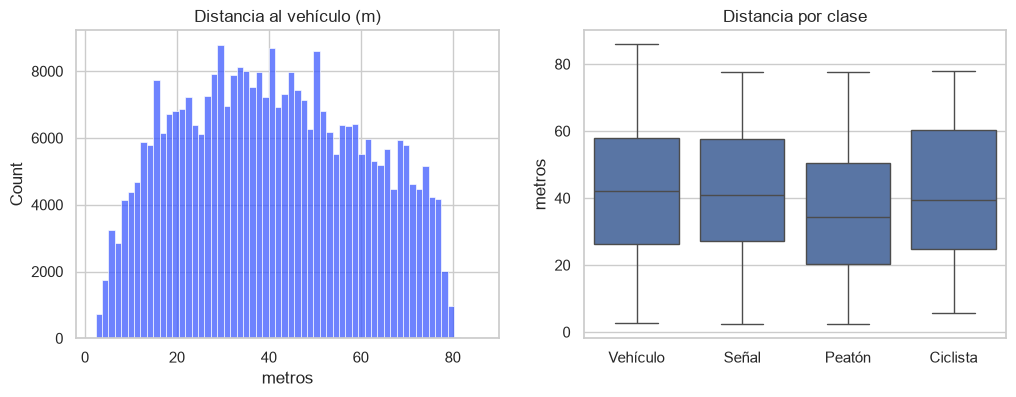

In [10]:
print(df["distancia_vehiculo"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["distancia_vehiculo"], bins=60, ax=axes[0], color="#3D5AFE")
axes[0].set_title("Distancia al vehículo (m)")
axes[0].set_xlabel("metros")
sns.boxplot(data=df, x="type_nombre", y="distancia_vehiculo", order=ORDEN_CLASES, ax=axes[1])
axes[1].set_title("Distancia por clase")
axes[1].set_xlabel("")
axes[1].set_ylabel("metros")
fig.savefig(PLOTS / "01_distancia.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** _(rango de distancias, forma de la distribución y si cambia según la clase)._

**Hallazgo:** los objetos están entre 2,3 y 85,9 metros del vehículo, y el promedio es de unos 41 metros. La mitad de los objetos está entre 25 y 57 metros. No hay un solo pico: la distancia se reparte por todo el rango. Los peatones tienden a estar un poco más cerca que las otras clases. Como los valores se reparten tanto, sirve bien para un problema de regresión.

**Hallazgo:** la distancia al vehículo va de 2,3 a 85,9 m (media 40,8 m, mediana 40,1 m) y se reparte de forma amplia, sin un pico marcado. Casi no hay detecciones más allá de unos 80 m. Por clase, los peatones se concentran más cerca que el resto. Como el rango es amplio y continuo, es una buena variable objetivo para regresión.

## 5. ¿Se puede estimar la distancia a partir de lo que mide el LiDAR?

A mayor distancia, menos puntos del LiDAR caen dentro de la caja de un objeto. Esa es la relación física en la que se apoya la regresión.

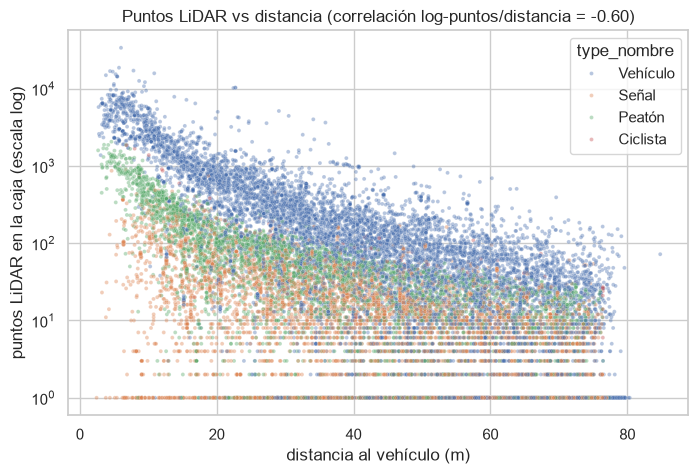

In [6]:
muestra = df.sample(min(20_000, len(df)), random_state=RANDOM_STATE).copy()
muestra["puntos"] = muestra["num_lidar_points_in_box"].clip(lower=1)  # para poder usar escala log

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=muestra, x="distancia_vehiculo", y="puntos", hue="type_nombre",
                hue_order=[c for c in ORDEN_CLASES if c in muestra["type_nombre"].unique()],
                s=8, alpha=0.4, ax=ax)
ax.set_yscale("log")
corr = np.corrcoef(np.log1p(df["num_lidar_points_in_box"]), df["distancia_vehiculo"])[0, 1]
ax.set_title(f"Puntos LiDAR vs distancia (correlación log-puntos/distancia = {corr:.2f})")
ax.set_ylabel("puntos LiDAR en la caja (escala log)")
ax.set_xlabel("distancia al vehículo (m)")
fig.savefig(PLOTS / "01_puntos_vs_distancia.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** _(¿la relación es fuerte o dispersa? ¿qué clase se aparta del patrón?)._

**Hallazgo:** hay una relación clara y no lineal: al aumentar la distancia, caen los puntos LiDAR dentro de la caja (correlación entre log-puntos y distancia = −0,60). Los vehículos alcanzan los valores más altos de puntos, así que el tipo y el tamaño del objeto ayudan a estimar la distancia. Pero a una misma distancia los puntos varían hasta en 2 o 3 órdenes de magnitud, y hay objetos con 0 o 1 punto a cualquier distancia. Por eso no esperamos una regresión perfecta, y está bien: es un trade-off que vamos a interpretar.

## 6. ¿Qué distingue a cada clase? Tamaño y rapidez

Esto anticipa qué variables le servirán a los clasificadores.

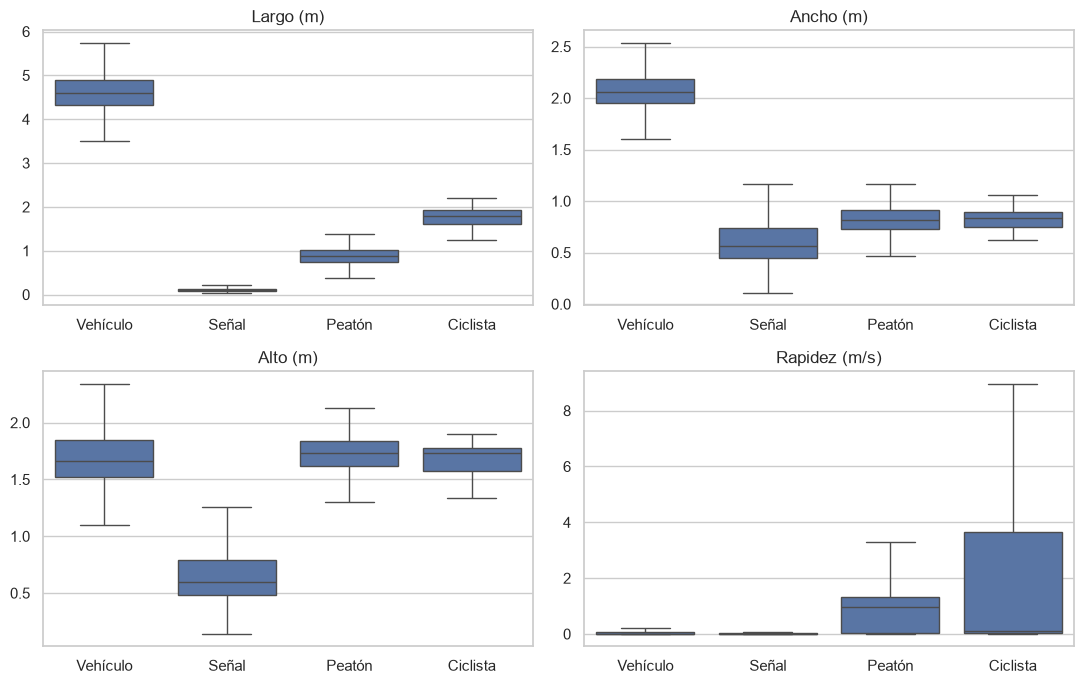

In [7]:
rapidez = np.sqrt(df["speed_x"] ** 2 + df["speed_y"] ** 2 + df["speed_z"] ** 2)
datos = df.assign(rapidez=rapidez)
variables = {"box_size_x": "Largo (m)", "box_size_y": "Ancho (m)",
             "box_size_z": "Alto (m)", "rapidez": "Rapidez (m/s)"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, titulo) in zip(axes.ravel(), variables.items()):
    sns.boxplot(data=datos, x="type_nombre", y=col, order=ORDEN_CLASES, showfliers=False, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(PLOTS / "01_tamano_rapidez_por_clase.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
datos.groupby("type_nombre")[["box_size_x", "box_size_y", "box_size_z", "rapidez"]].median().round(2)

,box_size_x,box_size_y,box_size_z,rapidez
type_nombre,,,,
Ciclista,1.79,0.83,1.73,0.10
Peatón,0.88,0.81,1.73,0.96
Señal,0.10,0.57,0.60,0.01
Vehículo,4.59,2.06,1.66,0.01


**Hallazgo:** _(qué clases se separan fácilmente por tamaño y cuáles se parecen)._

**Hallazgo:** el tamaño separa bien a casi todas las clases. Los vehículos son los más grandes (mediana de 4,59 m de largo y 2,06 m de ancho). Las señales son muy delgadas (0,10 m de largo) y bajas (0,60 m de alto). Peatones y ciclistas se parecen mucho: casi el mismo ancho (0,81 y 0,83 m) y el mismo alto (1,73 m). Lo que los distingue es el largo: el del ciclista (1,79 m) es el doble que el del peatón (0,88 m). La rapidez ayuda menos de lo esperado: la mayoría de los vehículos y las señales están quietos (mediana de 0,01 m/s), y entre peatones y ciclistas la mediana del ciclista es incluso menor (0,10 contra 0,96 m/s), porque muchos aparecen detenidos. Aun así, algunos ciclistas llegan a velocidades bastante más altas que los peatones. En resumen, lo más difícil será separar peatón de ciclista, y la variable clave para hacerlo es el largo.

## 7. Estructura de los datos: segmentos y objetos repetidos

Un mismo objeto aparece en muchos frames consecutivos. Si mezclamos esas filas al azar entre entrenamiento y prueba, el modelo vería en entrenamiento al mismo objeto que luego evalúa, y las métricas saldrían infladas. Por eso la validación cruzada se hará **agrupando por segmento**.

In [8]:
por_segmento = (df.groupby("key_segment_context_name")["type_nombre"].value_counts()
                .unstack(fill_value=0).reindex(columns=ORDEN_CLASES, fill_value=0))
print(por_segmento.describe().round(1))
print("\nSegmentos sin ciclistas:", (por_segmento["Ciclista"] == 0).sum(), "de", len(por_segmento))
print("Segmentos sin peatones:", (por_segmento["Peatón"] == 0).sum(), "de", len(por_segmento))

filas_por_objeto = df.groupby("key_laser_object_id").size()
print(f"\nFrames por objeto: mediana={filas_por_objeto.median():.0f}, máximo={filas_por_objeto.max()}")

objetos_por_clase = (df.groupby("type_nombre")["key_laser_object_id"].nunique()
                     .reindex(ORDEN_CLASES).fillna(0).astype(int))
print("\nObjetos únicos por clase:")
print(objetos_por_clase)

type_nombre  Vehículo   Señal   Peatón  Ciclista
count            30.0    30.0     30.0      30.0
mean           5423.2  3218.8   2390.5      58.9
std            3677.8  1987.6   4714.2      98.2
min             358.0     0.0      0.0       0.0
25%            2594.8  1728.2    147.0       0.0
50%            4778.5  3151.0    600.5       0.0
75%            7217.5  4383.5   1623.8      99.2
max           15196.0  7995.0  19121.0     317.0

Segmentos sin ciclistas: 19 de 30
Segmentos sin peatones: 3 de 30

Frames por objeto: mediana=90, máximo=199

Objetos únicos por clase:
type_nombre
Vehículo    1639
Señal        976
Peatón       586
Ciclista      17
Name: key_laser_object_id, dtype: int64


**Hallazgo:** _(cuántos objetos únicos reales hay de la clase Ciclista, y qué implica para evaluar un modelo sobre esa clase)._

**Hallazgo:** aunque hay más de 332 mil filas, en realidad son solo 3.218 objetos distintos, porque cada objeto aparece en muchos frames seguidos (un frame es una lectura del sensor en un instante). Un objeto típico sale unas 90 veces, y algunos hasta 199. De ciclistas hay apenas 17 objetos distintos, y están en solo 11 de los 30 segmentos. Esto tiene dos consecuencias. Primero, al evaluar los modelos separaremos los datos por segmento, para que ninguno se pruebe con objetos que ya vio al entrenar. Segundo, los resultados sobre ciclistas hay que tomarlos con cuidado, porque se basan en muy pocos casos.

**Hallazgo:** aunque hay 332.741 filas, solo hay 3.218 objetos distintos: cada uno aparece en una mediana de 90 frames, y hasta en 199. Por clase hay 1.639 vehículos, 976 señales, 586 peatones y apenas **17 ciclistas**, presentes en 11 de los 30 segmentos (19 no tienen ninguno). Además, 3 segmentos no tienen peatones, y la cantidad de peatones por segmento va de 0 a 19.121. Esto implica dos cosas: hay que validar agrupando por segmento, para no evaluar con objetos que el modelo ya vio, y los resultados sobre la clase Ciclista serán poco confiables, porque se apoyan en solo 17 objetos.

## 8. Conclusiones del EDA y decisiones para el modelado

- **Datos:** 332.741 detecciones de 30 segmentos, sin duplicados. Los únicos nulos están en `difficulty_level` (90,9 %), columnas que no usaremos.
- **Clases desbalanceadas:** los ciclistas son el 0,53 % de las filas y solo 17 objetos distintos. Por eso evaluaremos con balanced accuracy y F1 macro, no solo con accuracy, y mostraremos el recall por clase avisando que el de ciclista se basa en pocos casos.
- **Variables útiles:** tamaño (largo, ancho y alto), rapidez y puntos LiDAR. La pareja más difícil de separar es peatón y ciclista: se parecen en ancho y alto, y el largo es lo que más los distingue.
- **Regresión:** la distancia al vehículo (de 2,3 a 85,9 m) se relaciona con los puntos LiDAR (correlación de -0,60). No usaremos `box_center_x/y/z` como entrada, porque con ellos la distancia se calcula directo.
- **Validación:** cada objeto aparece unas 90 veces seguidas, así que separaremos los datos por segmento para no inflar las métricas.